/tmp/ipykernel_3048/3455252548.py:54: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend(title='Condition', bbox_to_anchor=(1.05, 1), loc='upper left')


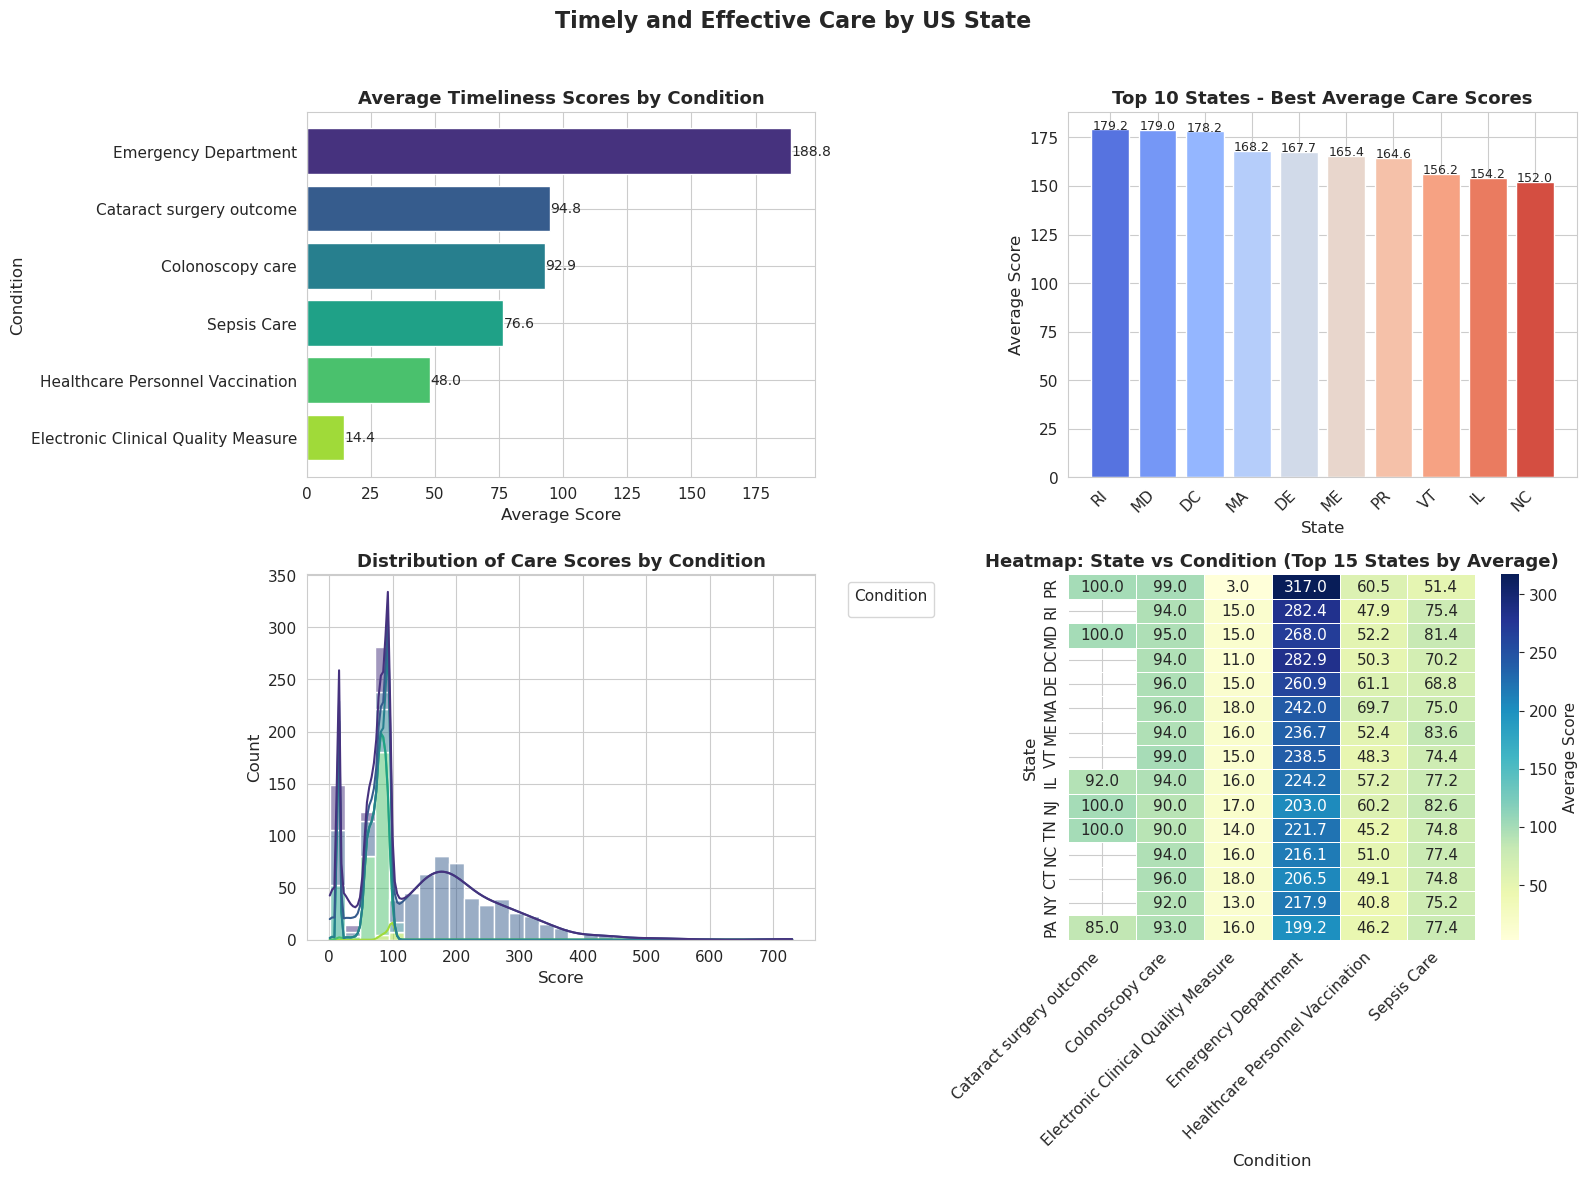

Visualization saved as 'timely_effective_care_visualization.png'

Dataset Summary:
Total records: 1077
States/Territories: 52
Conditions: 6
Score range: 1.0 to 730.0


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

# Load the data
care_state = pd.read_csv('https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-04-08/care_state.csv')

# Clean the data
care_state['score'] = pd.to_numeric(care_state['score'], errors='coerce')
care_state = care_state.dropna(subset=['score'])

# Set the style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 10)
plt.rcParams['font.size'] = 11

# Create a figure with subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Timely and Effective Care by US State', fontsize=16, fontweight='bold', y=0.98)

# Color palette
palette = sns.color_palette('viridis', n_colors=len(care_state['condition'].unique()))

# Plot 1: Average scores by condition
ax1 = axes[0, 0]
condition_scores = care_state.groupby('condition')['score'].mean().sort_values(ascending=False)
bars1 = ax1.barh(condition_scores.index, condition_scores.values, color=palette[:len(condition_scores)])
ax1.set_xlabel('Average Score', fontsize=12)
ax1.set_ylabel('Condition', fontsize=12)
ax1.set_title('Average Timeliness Scores by Condition', fontsize=13, fontweight='bold')
ax1.invert_yaxis()
for i, v in enumerate(condition_scores.values):
    ax1.text(v + 0.1, i, f'{v:.1f}', va='center', fontsize=10)

# Plot 2: Top 10 states with best average scores
ax2 = axes[0, 1]
state_scores = care_state.groupby('state')['score'].mean().sort_values(ascending=False).head(10)
bars2 = ax2.bar(range(len(state_scores)), state_scores.values, color=sns.color_palette('coolwarm', len(state_scores)))
ax2.set_xticks(range(len(state_scores)))
ax2.set_xticklabels(state_scores.index, rotation=45, ha='right')
ax2.set_ylabel('Average Score', fontsize=12)
ax2.set_xlabel('State', fontsize=12)
ax2.set_title('Top 10 States - Best Average Care Scores', fontsize=13, fontweight='bold')
for i, v in enumerate(state_scores.values):
    ax2.text(i, v + 0.1, f'{v:.1f}', ha='center', fontsize=9)

# Plot 3: Distribution of scores across all measures
ax3 = axes[1, 0]
sns.histplot(data=care_state, x='score', hue='condition', multiple='stack', ax=ax3, palette=palette, kde=True)
ax3.set_xlabel('Score', fontsize=12)
ax3.set_ylabel('Count', fontsize=12)
ax3.set_title('Distribution of Care Scores by Condition', fontsize=13, fontweight='bold')
ax3.legend(title='Condition', bbox_to_anchor=(1.05, 1), loc='upper left')

# Plot 4: Heatmap of state vs condition (average scores)
ax4 = axes[1, 1]
pivot_data = care_state.pivot_table(values='score', index='state', columns='condition', aggfunc='mean')
# Select top 15 states for readability
top_states = pivot_data.mean(axis=1).nlargest(15).index
pivot_subset = pivot_data.loc[top_states]

sns.heatmap(pivot_subset, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=.5, ax=ax4, cbar_kws={'label': 'Average Score'})
ax4.set_title('Heatmap: State vs Condition (Top 15 States by Average)', fontsize=13, fontweight='bold')
ax4.set_xlabel('Condition', fontsize=12)
ax4.set_ylabel('State', fontsize=12)
plt.xticks(rotation=45, ha='right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('timely_effective_care_visualization.png', dpi=300, bbox_inches='tight')
plt.show()

print("Visualization saved as 'timely_effective_care_visualization.png'")
print(f"\nDataset Summary:")
print(f"Total records: {len(care_state)}")
print(f"States/Territories: {care_state['state'].nunique()}")
print(f"Conditions: {care_state['condition'].nunique()}")
print(f"Score range: {care_state['score'].min():.1f} to {care_state['score'].max():.1f}")